# ¿Podemos anticipar al Banco Central?
**IMT2200 · Grupo 9 · Chile, 2010–2025**

Loreto Cornejo, Fernando Osses, Macarena Pérez y Álvaro Recabarren.

**Pregunta.** ¿Cuánta señal añade el dólar observado al historial de la TPM para anticipar si el Banco Central subirá, mantendrá o bajará la tasa? ¿Qué otros indicadores muestran diferencias descriptivas antes de cada tipo de decisión?

El corte es el cierre del último día hábil observado antes del **anuncio**, en hora de Santiago. En una reunión de dos días puede coincidir con el primer día de deliberación. Se evalúa el **signo** del cambio en puntos base. Una subida de 25 pb y otra de 100 pb cuentan como la misma clase.

El resultado principal usa reuniones ordinarias y datos respaldados por el historial oficial y la metodología del dólar. Las demás series se analizan con rezagos conservadores y se identifican como retrospectivas. El análisis es predictivo y descriptivo. Como antecedentes, el [DT 526 del BCCh](https://www.bcentral.cl/contenido/-/details/documento-de-trabajo-n-526) estudia la predicción de la dirección de la tasa y el [IPoM de marzo de 2022](https://www.bcentral.cl/documents/33528/3456057/Recuadro%2BV.3_Forward%2Bguidance%2Bde%2Bpol%C3%ADtica%2Bmonetaria%2By%2Bel%2Bcorredor%2Bpara%2Bla%2BTPM.pdf/2f1ded41-7f15-56a4-ddda-928e1ea20807?t=1648640788867) discute la reacción ante la actividad y la inflación.

In [1]:
from pathlib import Path
import sys

cwd = Path.cwd()
ROOT = next(p for p in (cwd, *cwd.parents) if (p / 'src/processing/estudio_final.py').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

from src.processing import estudio_final as estudio, figuras_final as figuras

OUT = ROOT / 'output/entrega_final/resultados'
OUT.mkdir(parents=True, exist_ok=True)
print(f'Python {sys.version.split()[0]} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}')

Python 3.14.3 | pandas 3.0.6 | scikit-learn 1.9.1


## 1. Del anuncio a una fila por reunión

1. El registro oficial identifica el anuncio aunque la TPM diaria quede plana. Regeneramos las etiquetas a partir de las fuentes conservadas y contrastamos el resultado con el archivo limpio.
2. Calculamos el corte con el calendario de observaciones de TPM y lo contrastamos con la fecha anterior de la serie de dólar. Es un contraste operativo entre dos series. Sus calendarios completos difieren en tres fechas y no se han certificado como calendario bancario universal.
3. Usamos la TPM vigente y el historial ya anunciado. El nivel posterior y el cambio de la reunión actual sirven para formar la etiqueta. Las variables de historial se desplazan una fila antes de calcular sus valores.
4. Para el dólar usamos como disponibilidad la **fecha de vigencia** y descartamos el anticipo referencial de la web. El BCCh calcula el valor con transacciones del día hábil bancario anterior y documenta publicación en el Diario Oficial y ausencia de revisiones estadísticas. Se contrastaron los valores del 16 y 18 de octubre de 2024. Excluimos las dos vigencias especiales 16–17/01/2018 de los retornos de dólar.

[Ficha del dólar observado, secciones Publicación y Revisión](https://www.bcentral.cl/documents/33528/2546026/Dolar_Observado.pdf/d8d86d97-9939-b71e-1d93-afe4eab3f743?t=1707422015118) · [Serie BDE F073.TCO.PRE.Z.D](https://si3.bcentral.cl/siete/ES/Siete/Cuadro/CAP_TIPO_CAMBIO/MN_TIPO_CAMBIO4/DOLAR_OBS_ADO?idSerie=F073.TCO.PRE.Z.D) · [Diario Oficial 16/10](https://www.diariooficial.interior.gob.cl/publicaciones/2024/10/16/43974/01/2558656.pdf) · [Diario Oficial 18/10](https://www.diariooficial.interior.gob.cl/publicaciones/2024/10/18/43976/01/2559788.pdf) · [Circular 802](https://www.bcentral.cl/documents/33528/133253/Circ802.pdf/370a37e6-8819-97da-a4c7-0da81b285645?t=1655120177283).

In [2]:
panel, vinculos, inventario = estudio.construir_panel(ROOT)
assert len(panel) == panel.id_reunion.nunique() == 161
assert panel.fecha_corte.lt(panel.fecha_decision).all()
assert panel.corte_coincide_usd.all()
assert panel.dolar_ret_20_referencia.le(panel.fecha_corte).all()
assert panel.dolar_ret_20_inicio.lt(panel.dolar_ret_20_referencia).all()
assert panel.ipc_boletin_fecha_disponible.dropna().le(panel.loc[panel.ipc_boletin_valor.notna(), 'fecha_corte']).all()
print(f'{panel.corte_coincide_usd.sum()}/{len(panel)} fechas de corte coincidentes.')
campos = ['id_reunion', 'fecha_corte', 'fecha_decision', 'tpm_previa_pct', 'dolar_ret_20',
          'ipc_boletin_fecha_disponible', 'ipc_boletin_valor', 'decision']
display(panel.loc[panel.ipc_boletin_valor.notna(), campos].round(2))

161/161 fechas de corte coincidentes.


1307903450.py:11: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(panel.loc[panel.ipc_boletin_valor.notna(), campos].round(2))


,id_reunion,fecha_corte,fecha_decision,tpm_previa_pct,dolar_ret_20,ipc_boletin_fecha_disponible,ipc_boletin_valor,decision
150,RPM_20240903,2024-09-02,2024-09-03,5.75,-2.66,2024-08-08,0.7,baja
151,RPM_20241017,2024-10-16,2024-10-17,5.50,0.40,2024-10-08,0.1,baja


## 2. Cobertura, faltantes y versiones de los datos

La cobertura respaldada cuenta **reuniones**. Para TPM y dólar aplica al histórico vigente y al retorno diario, respectivamente. En IPC indica el dato **mensual** tal como salió en los boletines del INE, con dos reuniones cubiertas. La columna de candidatos para IPC corresponde en cambio a inflación acumulada de la descarga retrospectiva. Las ocho series siguen sin una cobertura conjunta reconstruida.

| Serie | Asignación |
|---|---|
| Dólar | Retorno porcentual entre las últimas 20 cotizaciones válidas y la vigente al corte. Si la última tiene más de 7 días corridos, falta el retorno. |
| Cobre | Retorno de 20 cotizaciones en la descarga Cochilco. Usamos una fecha estrictamente anterior al corte. Si supera 10 días corridos, queda faltante. No tenemos hora de publicación ni versión histórica por fila. |
| IPC | Producto de 12 variaciones mensuales descargadas, hasta el mes de corte menos 2. La fecha de referencia tiene un máximo de 100 días. El ejemplo con boletín se guarda en campos separados. |
| IMACEC y desempleo | Crecimiento interanual del índice original y diferencia en pp de la desocupación de trimestre móvil. Hasta el mes de corte menos 3 y un máximo de 130 días desde la referencia. El IMACEC empalmado puede incorporar revisiones. |
| EEE | Mediana de TPM de **fin del mes informado**. Brecha con la TPM al corte usando el mes previo (hasta 75 días). No se atribuye a una RPM concreta. |
| IPC anual | Dato de diciembre etiquetado en enero en el Excel. Solo inventario. |

Para las diarias no se interpolan feriados sin cotización. Para las mensuales se conservan faltantes y los rezagos se calculan en meses de calendario, con referencia al primer día del período. Los rezagos acotan la referencia del candidato. El valor histórico publicado exige evidencia adicional. Las imputaciones que necesita la regresión se ajustan con la mediana del entrenamiento de cada paso.

In [3]:
cobertura = estudio.cobertura_panel(panel, inventario)
display(cobertura)
ordinarias = panel.loc[panel.tipo_reunion.eq('ordinaria')].reset_index(drop=True)
inicial = ordinarias.iloc[:estudio.N_INICIAL]
print('Reuniones ordinarias:', len(ordinarias))
display(panel.loc[~panel.tipo_reunion.eq('ordinaria'), ['fecha_decision', 'decision', 'tipo_reunion']])

,variable,frecuencia,unidad,filas_2010_2025,transformacion,n_candidato_transformado,n_con_respaldo,edad_mediana_dias,edad_max_dias,criterio
0,tpm_bcentral_diaria,diaria,%,3984,tpm_previa_pct,161,161,0.0,0.0,TPM vigente; evitar duplicarla
1,clp_usd,diaria,CLP/USD,3983,dolar_ret_20,161,161,0.0,0.0,Vigencia BCCh; retorno de 20 cotizaciones
2,cu_usd_lb,diaria,USD/libra,4042,cobre_ret_20,160,0,1.0,5.0,Fecha de cotización; faltan horas publicadas
3,desempleo_total_mensual,mensual,%,190,desemp_12m,144,0,104.0,122.0,Trimestre móvil; versión retrospectiva
4,exp_tpm_mensual_mediana,mensual,%,192,eee_brecha,161,0,43.0,61.0,Mes previo; horizonte de fin de mes
5,imacec_empalmado_original,mensual,2018=100,192,imacec_12m,158,0,104.0,122.0,Índice empalmado; sujeto a revisiones
6,ipc_general_mensual,mensual,%,192,ipc_12m,160,2,74.0,91.0,Boletines solo para el IPC mensual de ejemplo
7,ipc_general_anual,anual,%,16,no construida,0,0,NaN,NaN,Diciembre; excluido por frecuencia y redundancia


Reuniones ordinarias: 160


,fecha_decision,decision,tipo_reunion
113,2020-03-16,baja,extraordinaria


## 3. EDA por clase y por período

El gráfico de composición usa las 161 decisiones. Los boxplots y tablas de predictores usan las primeras 60 reuniones ordinarias para evitar inspeccionar la prueba al discutir transformaciones. Cada caja muestra la mediana y el 50 % central. La tabla indica el tamaño muestral por variable y clase.

El nivel de una serie larga puede mezclar épocas con escalas distintas. Comparamos nivel y cambio con las mismas filas y usamos retornos de 20 cotizaciones para dólar y cobre. En el IMACEC original la comparación anual atenúa la estacionalidad. Calculamos el acumulado de IPC sobre 12 meses a partir de variaciones mensuales. Para la EEE importa la distancia respecto de la TPM vigente.

decision,baja,mantiene,sube
periodo,,,
2010–13,3,33,12
2014–17,10,36,2
2018–21,5,22,6
2022–25,13,12,7


,variable,nombre,unidad,decision,n,mediana,q25,q75
0,ipc_12m,IPC acumulado a 12 meses,%,baja,9,3.968,2.934,4.695
1,ipc_12m,IPC acumulado a 12 meses,%,mantiene,38,2.832,1.630,3.606
2,ipc_12m,IPC acumulado a 12 meses,%,sube,12,2.365,1.807,2.885
3,imacec_12m,IMACEC original interanual,%,baja,9,2.419,1.609,3.055
4,imacec_12m,IMACEC original interanual,%,mantiene,36,4.653,3.095,6.161
5,imacec_12m,IMACEC original interanual,%,sube,12,7.041,6.378,7.882
6,desemp_12m,Cambio interanual del desempleo,pp,baja,9,-0.395,-0.495,-0.217
7,desemp_12m,Cambio interanual del desempleo,pp,mantiene,33,-0.588,-0.914,-0.363
8,desemp_12m,Cambio interanual del desempleo,pp,sube,1,-1.679,-1.679,-1.679
9,dolar_ret_20,Dólar observado a 20 cotizaciones,%,baja,9,1.851,-0.373,3.141


,serie,decision,n_comun,unidad_nivel,mediana_nivel,unidad_cambio,mediana_cambio
0,Dólar observado,baja,9,CLP/USD,554.050,% a 20 cotizaciones,1.851
1,Dólar observado,mantiene,39,CLP/USD,497.110,% a 20 cotizaciones,0.135
2,Dólar observado,sube,12,CLP/USD,479.865,% a 20 cotizaciones,-1.489
3,Cobre BML,baja,9,USD/libra,3.187,% a 20 cotizaciones,-1.666
4,Cobre BML,mantiene,38,USD/libra,3.388,% a 20 cotizaciones,-0.678
5,Cobre BML,sube,12,USD/libra,4.003,% a 20 cotizaciones,4.274
6,IMACEC original,baja,9,Índice,89.942,% interanual,2.419
7,IMACEC original,mantiene,36,Índice,86.500,% interanual,4.653
8,IMACEC original,sube,12,Índice,77.281,% interanual,7.041
9,Desempleo,baja,9,Nivel (%),6.144,Cambio interanual (pp),-0.395


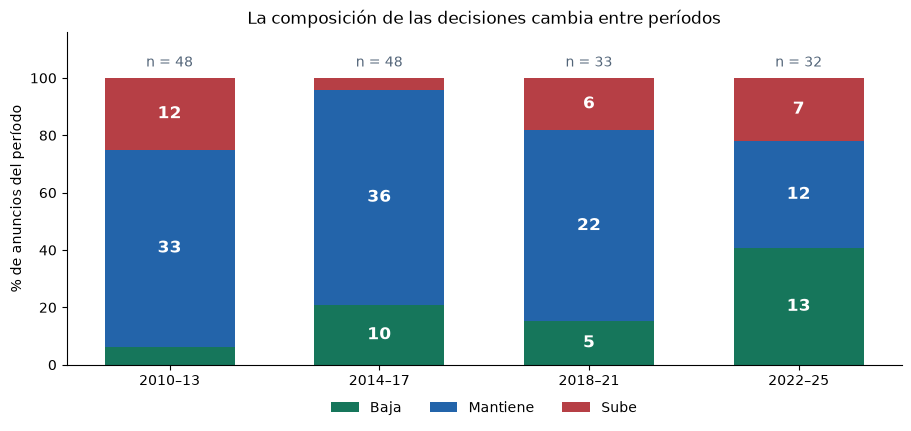

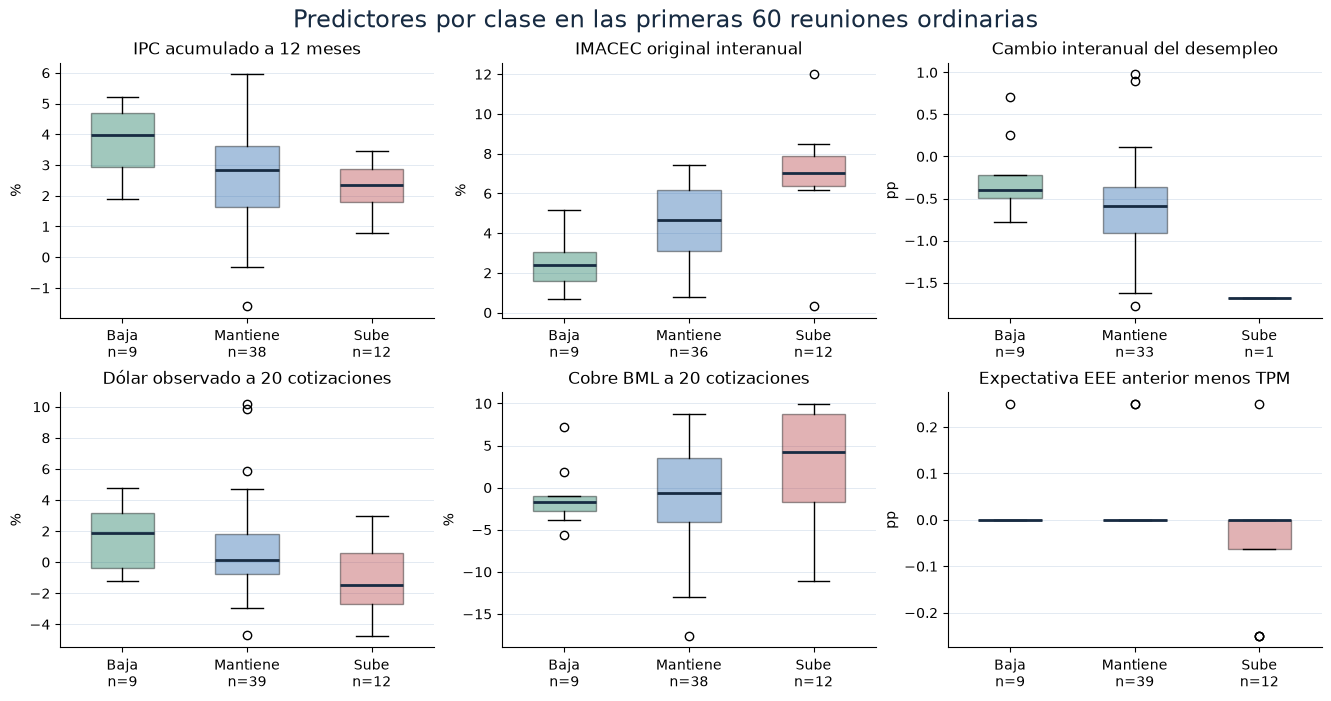

In [4]:
graf_periodos, conteos_periodos = figuras.periodos(panel)
graf_eda = figuras.distribuciones(inicial)
display(conteos_periodos)
display(estudio.estadisticas_eda(inicial).round(3))
display(pd.DataFrame(figuras.niveles_y_cambios(inicial)).round(3))
plt.show()

El IMACEC retrospectivo tiene mediana de 7,04 % en alzas y 2,42 % en bajas en el bloque inicial, con 12 y 9 casos. El dólar sube una mediana de 1,85 % en bajas y cae 1,49 % en alzas, con 9 y 12 casos. El IPC acumulado resulta menor en alzas que en bajas de este bloque. Por eso sería arriesgado trasladar una lectura simple a otros ciclos. Hay una sola alza con variación interanual de desempleo utilizable en el bloque inicial. La EEE del mes anterior tiene mediana de brecha cero en las tres clases, lo cual puede ocultar diferencias en casos particulares.

Estos patrones motivan probar el cambio del dólar, separar versiones retrospectivas y comparar el modelo con una referencia que capture rachas. Son asociaciones sobre el bloque inicial.

## 4. Protocolo de evaluación

Las primeras 60 reuniones ordinarias inicializan el entrenamiento. A partir de la reunión 61 se pronostica una decisión por vez y se amplía el entrenamiento cuando se conoce el resultado. Esta ventana creciente mantiene todos los casos pasados para cada ajuste y genera 100 pronósticos que nunca usan la etiqueta de su propia reunión. El anuncio extraordinario de marzo de 2020 se mantiene en el EDA y en el historial una vez conocido, pero no constituye un caso de entrenamiento o prueba.

- **Mayoría histórica** calcula la clase más frecuente de cada entrenamiento.
- **Persistencia** repite la decisión oficial anterior, incluidas las extraordinarias ya anunciadas.
- **Logística TPM** usa la tasa previa, el cambio de la última decisión y el acumulado de los últimos tres cambios.
- **Logística TPM + dólar** añade el retorno de 20 cotizaciones.
- **Sensibilidad retrospectiva** añade a este último IPC, IMACEC, desempleo y cobre con los rezagos documentados en la sección 2. Utiliza descargas posteriores y queda fuera de la conclusión predictiva principal.

Fijamos la regularización en C = 1 para ambas especificaciones principales y la sensibilidad, sin seleccionar hiperparámetros por resultados de prueba. La imputación y el escalamiento se vuelven a ajustar exclusivamente en cada bloque de entrenamiento.

Prueba: 15/01/2015 al 16/12/2025


,modelo,n,exactitud,f1_macro,exactitud_balanceada,n_baja,n_mantiene,n_sube,sens_baja,sens_mantiene,sens_sube
0,Mayoría histórica,100,0.64,0.260,0.333,21,64,15,0.000,1.000,0.000
1,Persistencia,100,0.74,0.694,0.694,21,64,15,0.619,0.797,0.667
2,Logística TPM,100,0.77,0.695,0.650,21,64,15,0.429,0.922,0.600
3,Logística TPM + dólar,100,0.76,0.691,0.656,21,64,15,0.476,0.891,0.600
4,Logística TPM + macro retrospectiva,100,0.77,0.719,0.695,21,64,15,0.476,0.875,0.733


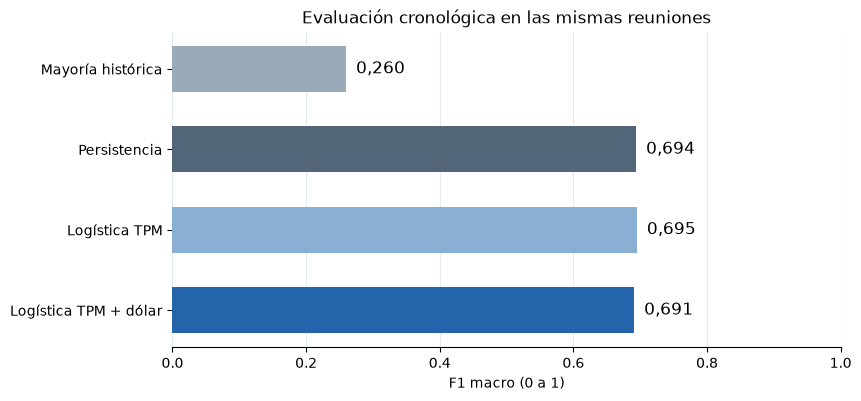

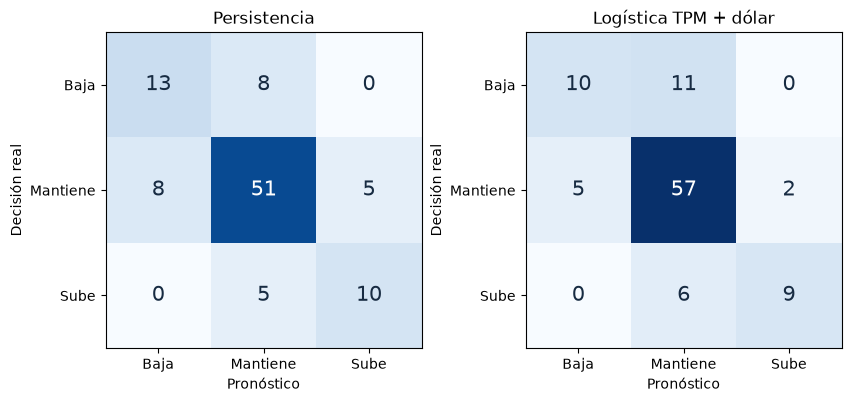

In [5]:
predicciones = estudio.evaluar(ordinarias)
modelos = estudio.MODELOS_PRINCIPALES + [estudio.MODELO_RETROSPECTIVO]
resultados, matrices = estudio.metricas(predicciones, modelos)
assert len(predicciones) == 100 and predicciones.id_reunion.is_unique
assert np.allclose(predicciones.filter(like='prob_tpm_dolar_').sum(axis=1), 1)
print(f'Prueba: {predicciones.fecha_decision.min():%d/%m/%Y} al {predicciones.fecha_decision.max():%d/%m/%Y}')
display(resultados.round(3))
graf_f1 = figuras.f1(resultados)
graf_matrices = figuras.confusiones(matrices)
plt.show()

In [6]:
# Soporte por bloque: evitar interpretar métricas agregadas cuando faltan clases.
por_periodo = []
for periodo, bloque in predicciones.groupby('periodo', sort=False):
    m, _ = estudio.metricas(bloque, estudio.MODELOS_PRINCIPALES)
    por_periodo.append(m.assign(periodo=periodo))
por_periodo = pd.concat(por_periodo, ignore_index=True)
display(por_periodo[['periodo', 'modelo', 'n', 'n_baja', 'n_mantiene', 'n_sube',
                    'sens_baja', 'sens_mantiene', 'sens_sube']].round(3))
display(predicciones[['fecha_decision', 'real', 'Logística TPM + dólar',
                      'prob_tpm_dolar_baja', 'prob_tpm_dolar_mantiene', 'prob_tpm_dolar_sube']].tail().round(3))

,periodo,modelo,n,n_baja,n_mantiene,n_sube,sens_baja,sens_mantiene,sens_sube
0,2014–17,Mayoría histórica,36,4,30,2,0.000,1.000,0.000
1,2014–17,Persistencia,36,4,30,2,0.500,0.867,0.000
2,2014–17,Logística TPM,36,4,30,2,0.000,0.967,0.000
3,2014–17,Logística TPM + dólar,36,4,30,2,0.250,0.967,0.000
4,2018–21,Mayoría histórica,32,4,22,6,0.000,1.000,0.000
5,2018–21,Persistencia,32,4,22,6,0.500,0.773,0.500
6,2018–21,Logística TPM,32,4,22,6,0.500,0.909,0.333
7,2018–21,Logística TPM + dólar,32,4,22,6,0.500,0.818,0.333
8,2022–25,Mayoría histórica,32,13,12,7,0.000,1.000,0.000
9,2022–25,Persistencia,32,13,12,7,0.692,0.667,1.000


2062808004.py:10: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  'prob_tpm_dolar_baja', 'prob_tpm_dolar_mantiene', 'prob_tpm_dolar_sube']].tail().round(3))


,fecha_decision,real,Logística TPM + dólar,prob_tpm_dolar_baja,prob_tpm_dolar_mantiene,prob_tpm_dolar_sube
95,2025-06-17,mantiene,mantiene,0.132,0.842,0.027
96,2025-07-29,baja,mantiene,0.174,0.809,0.017
97,2025-09-09,mantiene,mantiene,0.343,0.652,0.006
98,2025-10-28,mantiene,mantiene,0.129,0.850,0.022
99,2025-12-16,baja,mantiene,0.129,0.850,0.021


## 5. Sensibilidad de la encuesta EEE

Sobre las mismas reuniones comparamos el signo de la mediana esperada menos la TPM vigente usando tres escenarios de fecha. La regla del día 13 reproduce una hipótesis del avance. El dato del mismo mes puede corresponder a información futura. El mes anterior es una aproximación más conservadora, aunque su horizonte de fin de mes puede haber expirado y la fecha de publicación no se cotejó encuesta por encuesta. Estas tres cifras cuantifican cuánto importa el supuesto temporal. Los puntajes quedan fuera de la evaluación principal.

In [7]:
eee = estudio.sensibilidad_eee(ordinarias, predicciones)
display(eee.round(3))

,modelo,n,exactitud,f1_macro,exactitud_balanceada,n_baja,n_mantiene,n_sube,sens_baja,sens_mantiene,sens_sube
0,EEE mes previo,100,0.80,0.712,0.687,21,64,15,0.524,0.938,0.600
1,EEE supuesto día 13,100,0.88,0.847,0.827,21,64,15,0.810,0.938,0.733
2,"EEE mismo mes, puede usar futuro",100,0.90,0.865,0.848,21,64,15,0.857,0.953,0.733


## 6. Conclusión

La referencia de mayoría acierta el 64 % y detecta cero alzas o bajas. Persistencia alcanza **0,694 de F1 macro** y la logística con estado de TPM **0,695**. Al añadir dólar el F1 macro baja a **0,691**, aunque la exactitud global sube de 74 % en persistencia a 76 %. La logística con dólar detecta 10/21 bajas y 9/15 alzas. Persistencia detecta 13/21 y 10/15. Con 15 alzas, un acierto cambia su sensibilidad en 6,7 puntos porcentuales. El desempeño cercano al de persistencia deja poca evidencia de mejora estable a este horizonte.

La sensibilidad macro llega a 0,719 con los datos retrospectivos. Ese puntaje debe volver a evaluarse con valores históricos publicados. La EEE pasa de 0,712 con el mes previo a 0,847 con el supuesto del día 13, lo que refuerza la importancia de reconstruir fechas y preservar el horizonte de la encuesta. La evaluación reutiliza ciclos adyacentes y los modelos se probaron después de un avance exploratorio. Es una evaluación cronológica histórica, sin confirmación prospectiva independiente. El estudio tampoco estima efectos causales ni la magnitud de cambios de tasa.

In [8]:
# Exportación de los mismos datos y gráficos que alimentan presentación y guiones.
panel.to_csv(OUT / 'panel_por_reunion.csv', index=False)
cobertura.to_csv(OUT / 'cobertura.csv', index=False)
estudio.estadisticas_eda(inicial).to_csv(OUT / 'eda_por_clase.csv', index=False)
conteos_periodos.to_csv(OUT / 'decisiones_por_periodo.csv')
predicciones.to_csv(OUT / 'predicciones.csv', index=False)
resultados.to_csv(OUT / 'metricas.csv', index=False)
eee.to_csv(OUT / 'sensibilidad_eee.csv', index=False)
por_periodo.to_csv(OUT / 'sensibilidad_por_periodo.csv', index=False)
for nombre, grafico in [('decisiones_por_periodo', graf_periodos), ('eda_por_clase', graf_eda),
                       ('f1_macro', graf_f1), ('matrices_confusion', graf_matrices)]:
    grafico.savefig(OUT / f'{nombre}.png', dpi=185, facecolor='white')
print('Exportados en output/entrega_final/resultados.')

Exportados en output/entrega_final/resultados.
